In [1]:
import pip

def import_or_install(package):
    try:
        __import__(package)
    except ImportError:
        pip.main(['install', package])  

In [2]:
## Correr esta celda para instalar las librerías necesarias para correr el notebook.
libraries = [
"pandas",  
"numpy", 
"ipython",
"ipykernel",
"jupyter",
"matplotlib",
"notebook",
"seaborn",
"numba"]

for lib in libraries:
    import_or_install(lib)

Please see https://github.com/pypa/pip/issues/5599 for advice on fixing the underlying issue.
To avoid this problem you can invoke Python with '-m pip' instead of running pip directly.


error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.11/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.

In [3]:
import requests
import os
import re
import time


from numba import njit, prange
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def random_matrix(N, RANGE):
    """Genera una matriz aleatoria de tamaño NxN con valores en el rango [-RANGE, RANGE]."""
    return np.random.uniform(-RANGE, RANGE, (N, N))


@njit(parallel=True)
def matmul_numba(A, B, C, N):
    # Inicializar C a cero dentro del kernel para evitar dependencias externas
    for i in range(N):
        for j in range(N):
            C[i, j] = 0.0
            
    # Paralelismo de datos en el loop externo
    for i in prange(N):
        for k in range(N):
            for j in range(N):
                C[i, j] += A[i, k] * B[k, j]

In [5]:
A = random_matrix(2048, 10)
B = random_matrix(2048, 10)
C = np.zeros((2048, 2048), dtype=np.float64)
N = 2048

print("Ejecutando warm-up (compilación JIT)...")
matmul_numba(A, B, C, N)
    
threads_list = [1, 2, 4, 8]
results = []

filename = "resultados-py-alg-1.txt"

print("=== Numba: Paralelismo de Datos con Numba ===\n")
print(f"Tamaño de matriz: N = {N}")

# Abrir el archivo para escritura
with open(filename, 'w') as f:
    # Escribir encabezado idéntico al estilo C++
    f.write("Algoritmo: Multiplicación de Matrices con Numba\n")
    f.write(f"Tamaño de Matriz (N): {N}\n")
    f.write("Threads\tTiempo (ms)\tSpeedup (vs P=1)\tEficiencia (vs P=1)\n")
    f.write("-" * 60 + "\n")

    time_p1 = 0.0 # Variable para guardar el tiempo del caso base (1 thread)

    for p in threads_list:
        C[:] = 0.0 
        
        # Nota: En versiones recientes de Numba, set_num_threads() es preferible
        # si está disponible, pero NUMBA_NUM_THREADS sigue funcionando en muchos casos.
        os.environ['NUMBA_NUM_THREADS'] = str(p)
        
        start = time.perf_counter()
        matmul_numba(A, B, C, N)
        end = time.perf_counter()
        
        elapsed_ms = (end - start) * 1000
        
        # Guardar tiempo de referencia si es p=1
        if p == 1:
            time_p1 = elapsed_ms
            
        # Calcular Speedup y Eficiencia
        # Evitamos división por cero si time_p1 fuera 0 (improbable)
        speedup = time_p1 / elapsed_ms if elapsed_ms > 0 else 0
        efficiency = speedup / p if p > 0 else 0

        # Imprimir en consola con formato alineado
        print(f"Threads: {p:<5} Tiempo: {elapsed_ms:.2f} ms\tSpeedup: {speedup:.2f}\tEficiencia: {efficiency:.2f}")
        
        # Escribir en el archivo separado por tabuladores
        f.write(f"{p}\t{elapsed_ms:.2f}\t{speedup:.2f}\t{efficiency:.2f}\n")

print(f"\nResultados guardados en {filename}")

Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 2048
Threads: 1     Tiempo: 2512.97 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 2397.59 ms	Speedup: 1.05	Eficiencia: 0.52
Threads: 4     Tiempo: 2522.99 ms	Speedup: 1.00	Eficiencia: 0.25
Threads: 8     Tiempo: 2397.76 ms	Speedup: 1.05	Eficiencia: 0.13

Resultados guardados en resultados-py-alg-1.txt


In [6]:
def cargar_dataset_resultados(ruta_archivos):
    """
    Carga los resultados de los archivos .txt generados por los algoritmos
    y crea un DataFrame consolidado incluyendo Block Size si aplica.
    """
    data_list = []
    
    for nombre_key, ruta in ruta_archivos.items():
        if not os.path.exists(ruta):
            print(f"Advertencia: El archivo {ruta} no existe.")
            continue
            
        alg = "Desconocido"
        n_val = 2048 # Default para N
        block_size = None # Default para Block Size
        
        if 'alg1' in nombre_key or 'alg-1' in nombre_key:
            alg = "OpenMP"
        elif 'alg2' in nombre_key or 'alg-2' in nombre_key:
            alg = "Dividir para conquistar"
        elif 'py' in nombre_key or 'numba' in nombre_key:
            alg = "Numba"
            
        numeros_encontrados = re.findall(r'\d+', nombre_key)
        
        if numeros_encontrados:
            if alg == "Dividir para conquistar":
                if len(numeros_encontrados) >= 2:
                    block_size = int(numeros_encontrados[0])
                    n_val = int(numeros_encontrados[1])
                elif len(numeros_encontrados) == 1:
                    n_val = int(numeros_encontrados[0])
                    block_size = 64 # Valor por defecto si no se especifica
            else:
                n_val = int(numeros_encontrados[-1])

        try:
        
            with open(ruta, 'r') as f:
                lines = f.readlines()
            
            header_line_idx = None
            for i, line in enumerate(lines):
                if "Threads" in line and "\t" in line:
                    header_line_idx = i
                    break
            
            if header_line_idx is None:
                print(f"No se encontró encabezado de tabla en {ruta}")
                continue
                
            df_temp = pd.read_csv(
                ruta, 
                sep='\t', 
                skiprows=header_line_idx, 
                engine='python',
                on_bad_lines='skip'
            )
            
            df_temp.columns = df_temp.columns.str.strip()
            
            col_map = {}
            for col in df_temp.columns:
                if 'Thread' in col: col_map[col] = 'Threads'
                elif 'Tiempo' in col or 'Time' in col: col_map[col] = 'Tiempo_ms'
                elif 'Speedup' in col: col_map[col] = 'Speedup'
                elif 'Eficiencia' in col or 'Efficiency' in col: col_map[col] = 'Eficiencia'
            
            df_temp = df_temp.rename(columns=col_map)
            
            df_temp['Algoritmo'] = alg
            df_temp['N'] = n_val
            if block_size is not None:
                df_temp['Block_Size'] = block_size
            
            cols_numericas = ['Threads', 'Tiempo_ms', 'Speedup', 'Eficiencia']
            if 'Block_Size' in df_temp.columns:
                cols_numericas.append('Block_Size')
                
            for c in cols_numericas:
                if c in df_temp.columns:
                    df_temp[c] = pd.to_numeric(df_temp[c], errors='coerce')
            
            cols_finales = ['Algoritmo', 'N', 'Threads', 'Tiempo_ms']
            if 'Block_Size' in df_temp.columns: 
                cols_finales.append('Block_Size')
            if 'Speedup' in df_temp.columns: 
                cols_finales.append('Speedup')
            if 'Eficiencia' in df_temp.columns: 
                cols_finales.append('Eficiencia')
            
            # Eliminar filas donde el tiempo sea NaN
            df_temp = df_temp.dropna(subset=['Tiempo_ms'])
            
            data_list.append(df_temp[cols_finales])
            
        except Exception as e:
            print(f"Error procesando {ruta}: {e}")

    if data_list:
        final_df = pd.concat(data_list, ignore_index=True)
        return final_df
    else:
        return pd.DataFrame()

In [7]:
## Estos valores se retornan al correr el archivo algoritmo1 y algoritmo2, sin poner números.
computador_deseado = 1 # Cambia esto según la computadora que quieres usar
archivos_a_procesar = {
    "alg1": f"./resultados-computador-{computador_deseado}/resultados-alg1.txt",
    "alg2": f"./resultados-computador-{computador_deseado}/resultados-alg-2.txt",
    "py":   f"./resultados-computador-{computador_deseado}/resultados-py-alg-1.txt",
}

df_total = cargar_dataset_resultados(archivos_a_procesar)
df_total.head()

,Algoritmo,N,Threads,Tiempo_ms,Speedup,Eficiencia,Block_Size
0,OpenMP,1,1.0,908.530,1.000000,1.000000,NaN
1,OpenMP,1,2.0,1113.270,0.816092,0.408046,NaN
2,OpenMP,1,4.0,1013.050,0.896830,0.224207,NaN
3,OpenMP,1,8.0,905.589,1.003250,0.125406,NaN
4,Dividir para conquistar,2,1.0,6908.920,1.000000,1.000000,64.0


In [8]:
alg_2_n = {
    "alg2_32": f"./resultados-computador-{computador_deseado}/n-alg-2/32-resultados-alg-2.txt",
    "alg2_64": f"./resultados-computador-{computador_deseado}/n-alg-2/64-resultados-alg-2.txt",
    "alg2_128": f"./resultados-computador-{computador_deseado}/n-alg-2/128-resultados-alg-2.txt",
    "alg2_256": f"./resultados-computador-{computador_deseado}/n-alg-2/256-resultados-alg-2.txt",
    "alg2_512": f"./resultados-computador-{computador_deseado}/n-alg-2/512-resultados-alg-2.txt",
    "alg2_1024": f"./resultados-computador-{computador_deseado}/n-alg-2/1024-resultados-alg-2.txt",
    "alg2_2048": f"./resultados-computador-{computador_deseado}/n-alg-2/2048-resultados-alg-2.txt",
}

df_alg2 = cargar_dataset_resultados(alg_2_n)
df_alg2.head()

,Algoritmo,N,Threads,Tiempo_ms,Block_Size,Speedup,Eficiencia
0,Dividir para conquistar,32,1.0,1499.26,2,1.00000,1.000000
1,Dividir para conquistar,32,2.0,1195.74,2,1.25384,0.626918
2,Dividir para conquistar,32,4.0,1136.44,2,1.31926,0.329815
3,Dividir para conquistar,32,8.0,1266.01,2,1.18424,0.148029
4,Dividir para conquistar,64,1.0,1752.29,2,1.00000,1.000000


In [9]:
def plot_comparacion_paralela(df, nombre_figura="nombre.jpg", titulo= "Comparación de Algoritmos Paralelos"):
    # Configuración de estilo
    
    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Paleta de colores consistente
    palette = {"OpenMP": "#1f77b4", "Dividir para conquistar": "#ff7f0e", "Numba": "#2ca02c"}
    markers = {"OpenMP": "o", "Dividir para conquistar": "s", "Numba": "^"}

    # --- Gráfico 1: Tiempo de Ejecución ---
    sns.lineplot(data=df, x="Threads", y="Tiempo_ms", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[0], linewidth=2)
    axes[0].set_title("Tiempo de Ejecución (ms)", fontsize=14)
    axes[0].set_xlabel("Número de Threads")
    axes[0].set_ylabel("Tiempo (ms)")
    axes[0].legend(title="Algoritmo")

    # --- Gráfico 2: Speedup ---
    sns.lineplot(data=df, x="Threads", y="Speedup", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[1], linewidth=2)
    
    # Línea ideal de Speedup (S = p)
    threads_unicos = sorted(df['Threads'].unique())
    axes[1].plot(threads_unicos, threads_unicos, 'k--', label='Ideal (Lineal)', alpha=0.5)
    
    axes[1].set_title("Speedup S(p)", fontsize=14)
    axes[1].set_xlabel("Número de Threads")
    axes[1].set_ylabel("Speedup")
    axes[1].legend(title="Algoritmo")

    # --- Gráfico 3: Eficiencia ---
    sns.lineplot(data=df, x="Threads", y="Eficiencia", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[2], linewidth=2)
    
    # Línea ideal de Eficiencia (E = 1)
    axes[2].axhline(y=1.0, color='k', linestyle='--', alpha=0.5, label='Ideal (100%)')
    
    axes[2].set_title("Eficiencia E(p)", fontsize=14)
    axes[2].set_xlabel("Número de Threads")
    axes[2].set_ylabel("Eficiencia")
    axes[2].legend(title="Algoritmo")

    # Ajuste final del layout
    fig.suptitle(titulo, fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.savefig(nombre_figura, dpi=300, bbox_inches='tight')
    plt.show()


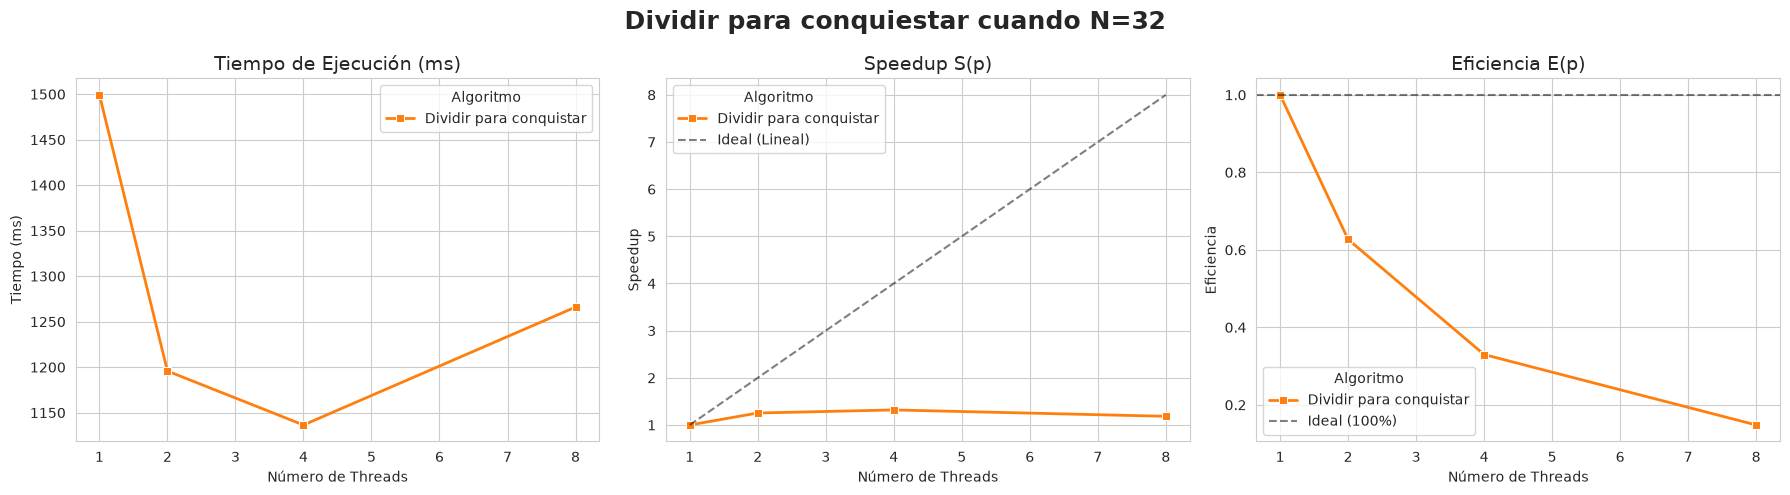

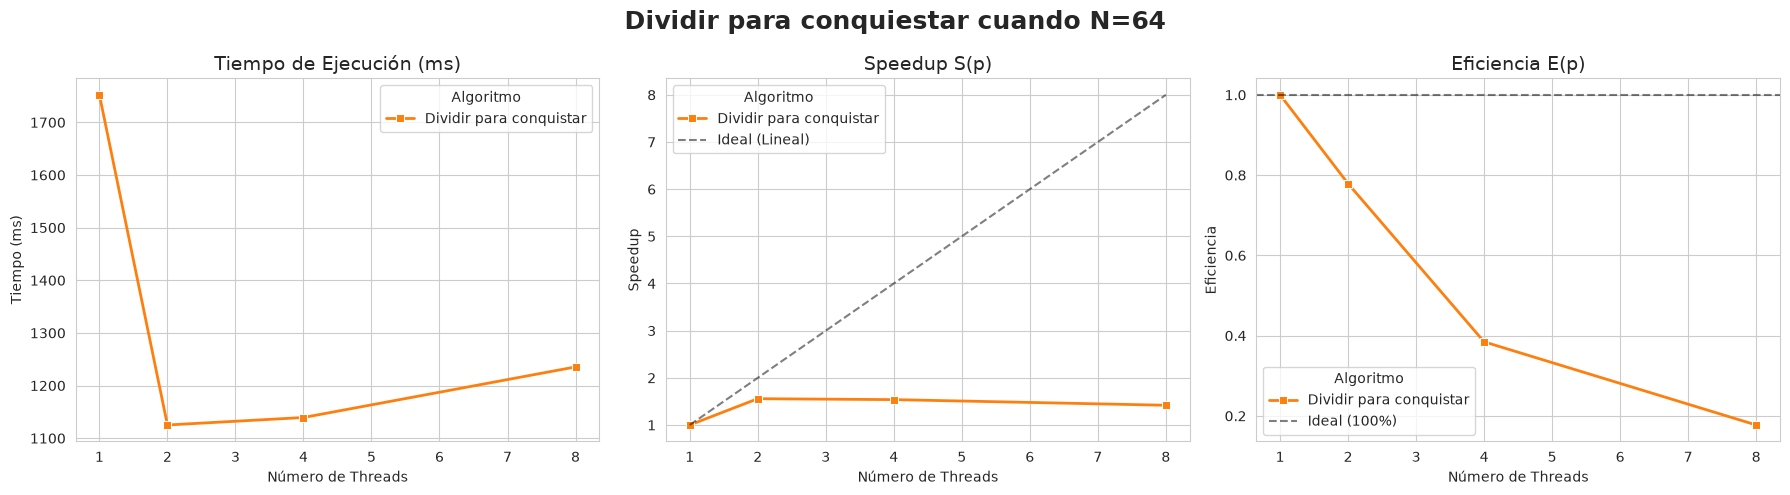

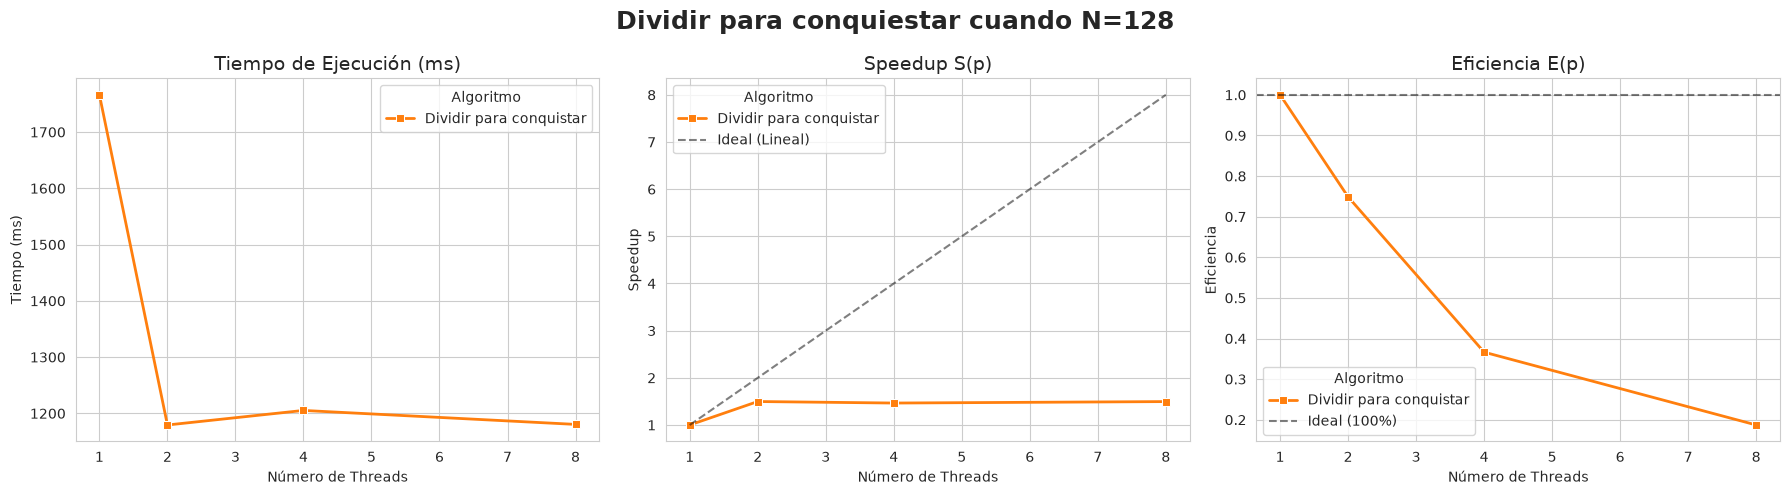

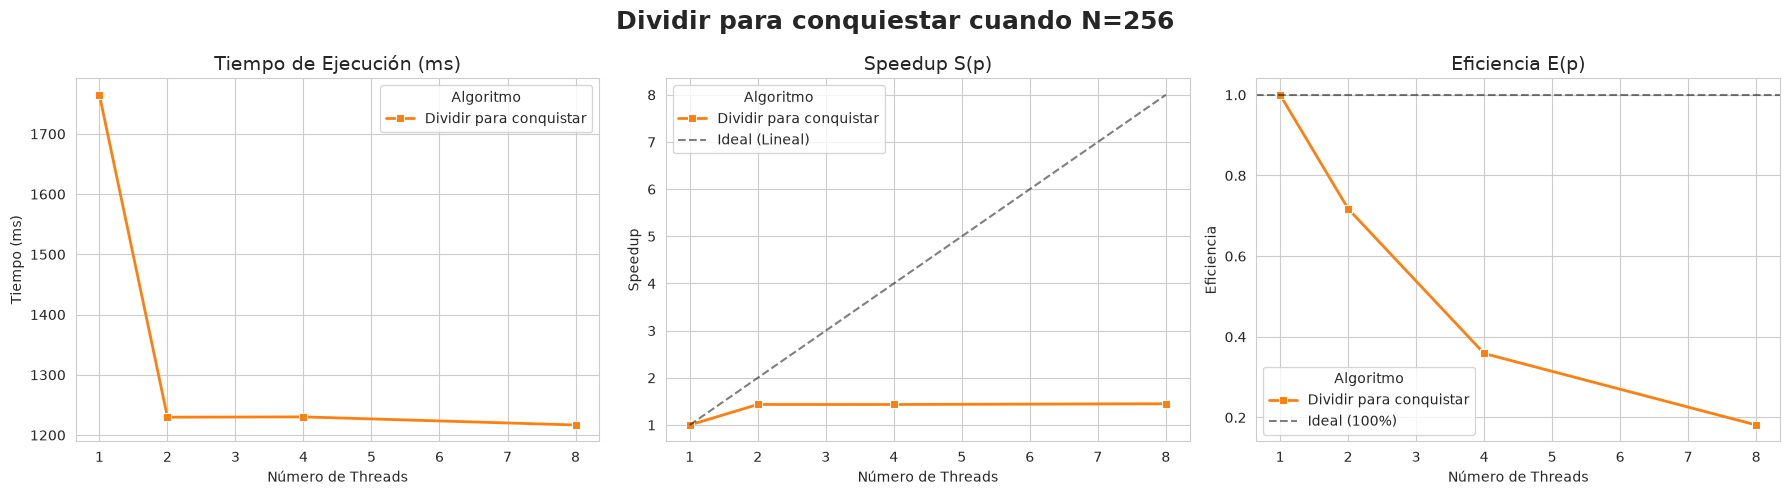

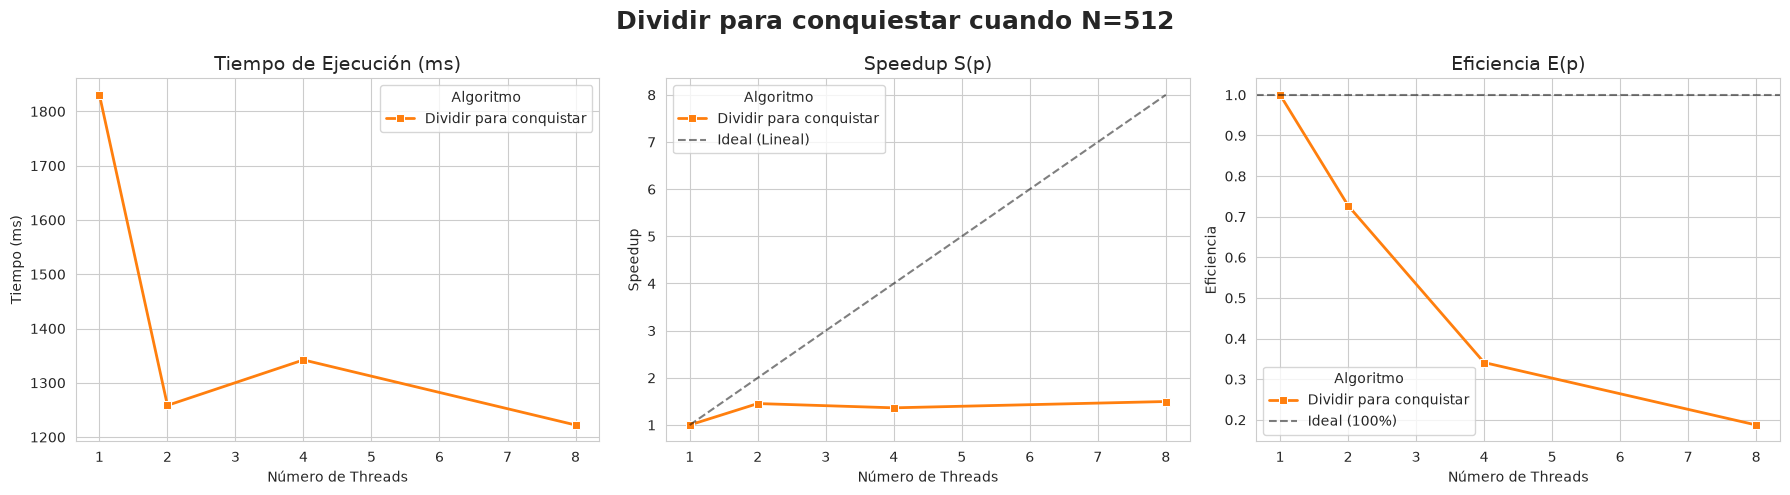

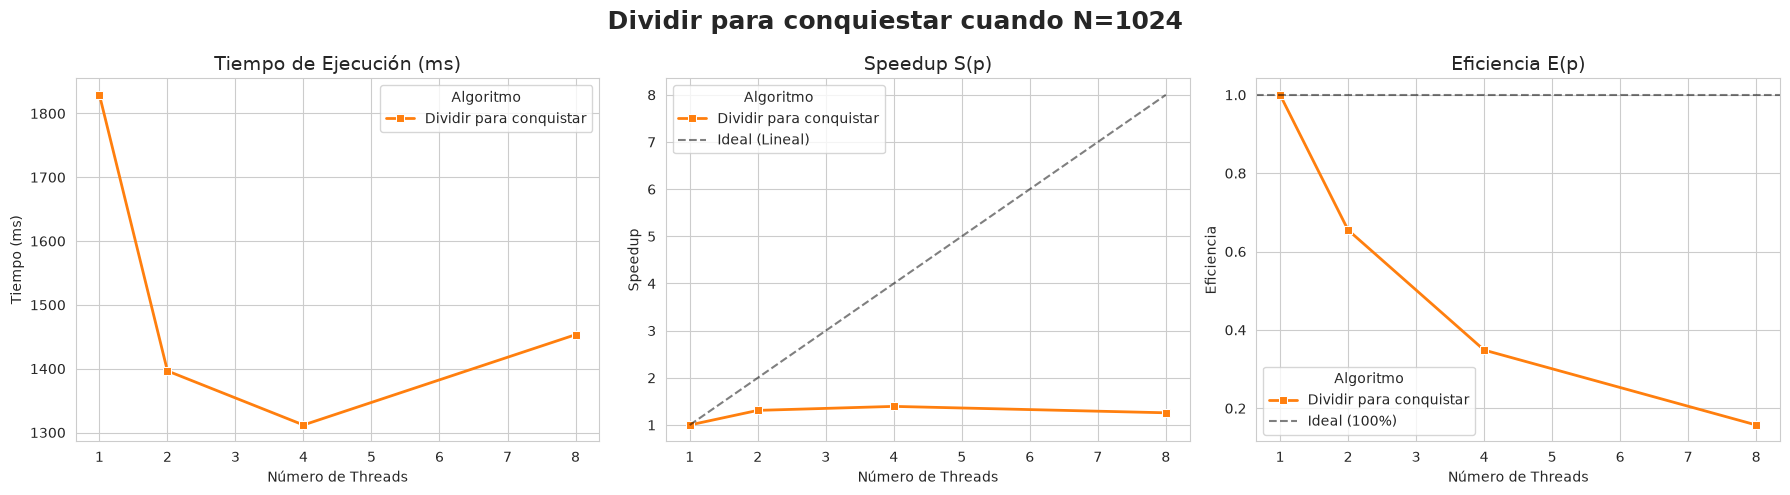

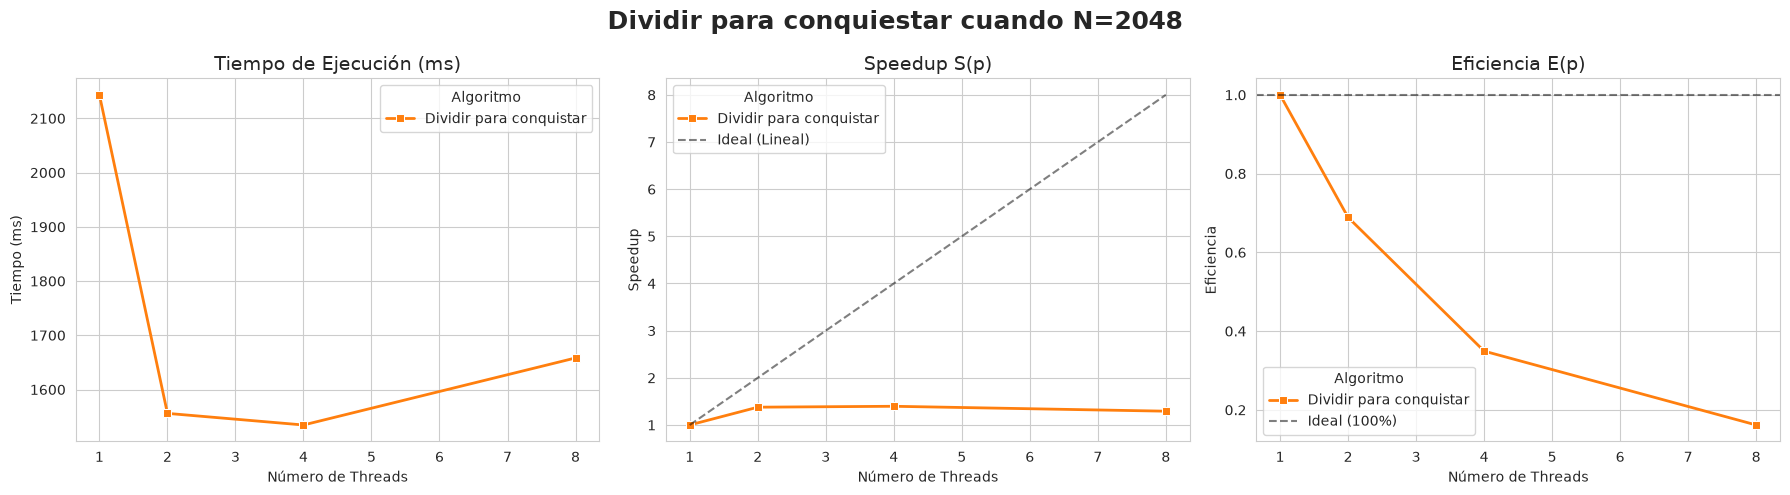

In [21]:
for n in [32, 64, 128, 256, 512, 1024, 2048]: 
    df_n_alg2 = df_alg2[df_alg2["N"] == n]
    plot_comparacion_paralela(df_n_alg2, titulo=f"Dividir para conquiestar cuando N={n}", nombre_figura=f"alg2_{n}")

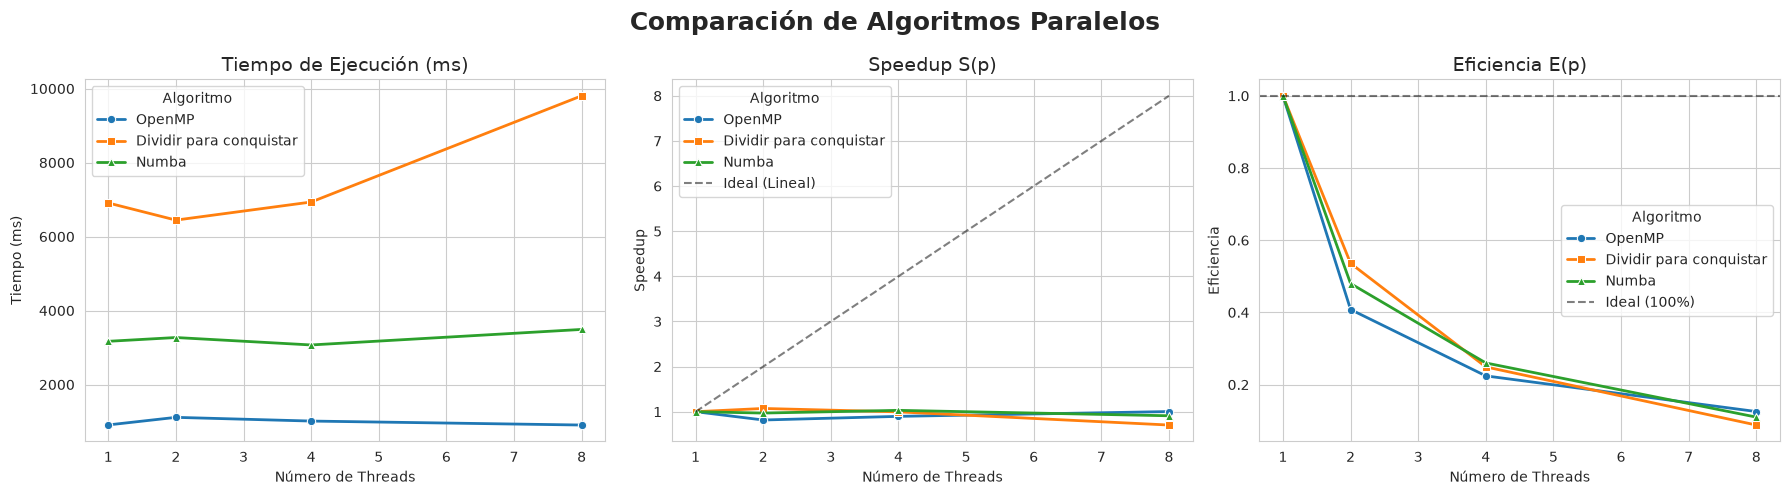

In [10]:
plot_comparacion_paralela(df_total, nombre_figura="comparacion_algoritmo.png")

In [11]:
for n in [1024, 2048, 4096]:
    print(f"\n=== Ejecutando para N = {n} ===")
    print("Ejecutando warm-up (compilación JIT)...")
    matmul_numba(A, B, C, n)
    
    threads_list = [1, 2, 4, 8]
    results = []
    print("=== Numba: Paralelismo de Datos con Numba ===\n")
    print(f"Tamaño de matriz: N = {n}")

    file_name = f"{n}-resultados-py-alg-1.txt"
    with open(file_name, 'w') as f:
        f.write("Algoritmo: Multiplicación de Matrices con Numba\n")
        f.write(f"Tamaño de Matriz (N): {N}\n")
        f.write("Threads\tTiempo (ms)\tSpeedup (vs P=1)\tEficiencia (vs P=1)\n")
        f.write("-" * 60 + "\n")
        
        time_p1 = 0.0 # Variable para guardar el tiempo del caso base (1 thread)
        for p in threads_list:
            C[:] = 0.0
            os.environ['NUMBA_NUM_THREADS'] = str(p)
            start = time.perf_counter()
            matmul_numba(A, B, C, n)
            end = time.perf_counter()
            elapsed_ms = (end - start) * 1000
            if p == 1:
                time_p1 = elapsed_ms
            speedup = time_p1 / elapsed_ms if elapsed_ms > 0 else 0
            efficiency = speedup / p if p > 0 else 0
            print(f"Threads: {p:<5} Tiempo: {elapsed_ms:.2f} ms\tSpeedup: {speedup:.2f}\tEficiencia: {efficiency:.2f}")
            f.write(f"{p}\t{elapsed_ms:.2f}\t{speedup:.2f}\t{efficiency:.2f}\n")
    print(f"\nResultados guardados en {file_name}")


=== Ejecutando para N = 1024 ===
Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 1024


Threads: 1     Tiempo: 248.21 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 311.34 ms	Speedup: 0.80	Eficiencia: 0.40
Threads: 4     Tiempo: 235.23 ms	Speedup: 1.06	Eficiencia: 0.26
Threads: 8     Tiempo: 253.69 ms	Speedup: 0.98	Eficiencia: 0.12

Resultados guardados en 1024-resultados-py-alg-1.txt

=== Ejecutando para N = 2048 ===
Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 2048
Threads: 1     Tiempo: 2385.20 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 2639.23 ms	Speedup: 0.90	Eficiencia: 0.45
Threads: 4     Tiempo: 2342.30 ms	Speedup: 1.02	Eficiencia: 0.25
Threads: 8     Tiempo: 2558.13 ms	Speedup: 0.93	Eficiencia: 0.12

Resultados guardados en 2048-resultados-py-alg-1.txt

=== Ejecutando para N = 4096 ===
Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 4096
Threads: 1     Tiempo: 17662.72 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2    

In [12]:
## Los resultados disponibles se hacen al correr los valores con algoritmox N 
## Siendo N el tamaño de la matriz, los archivos les cambie el nombre a mano
## Dejé disponible los resultados del computador en las carpetas "resultados-computador-x" para cada computador
computador_deseado = 1
archivos_a_procesar = {
    "alg1_1024": f"./resultados-computador-{computador_deseado}/1024-resultados-alg1.txt",
    "alg2_1024": f"./resultados-computador-{computador_deseado}/1024-resultados-alg-2.txt",
    "py_1024":   f"./resultados-computador-{computador_deseado}/1024-resultados-py-alg-1.txt",
    
    "alg1_2048": f"./resultados-computador-{computador_deseado}/2048-resultados-alg1.txt",
    "alg2_2048": f"./resultados-computador-{computador_deseado}/2048-resultados-alg-2.txt",
    "py_2048":   f"./resultados-computador-{computador_deseado}/2048-resultados-py-alg-1.txt",
    
    "alg1_4096": f"./resultados-computador-{computador_deseado}/4096-resultados-alg1.txt",
    "alg2_4096": f"./resultados-computador-{computador_deseado}/4096-resultados-alg-2.txt",
    "py_4096":   f"./resultados-computador-{computador_deseado}/4096-resultados-py-alg-1.txt",
}

dataset_N = cargar_dataset_resultados(archivos_a_procesar)

In [13]:
## Ordenar por threads y algoritmo 

dataset_N = dataset_N.sort_values(by=['N', 'Threads'])
dataset_N.head(10)

,Algoritmo,N,Threads,Tiempo_ms,Speedup,Eficiencia,Block_Size
0,OpenMP,1024,1.0,906.866,1.000000,1.000000,NaN
4,Dividir para conquistar,1024,1.0,951.695,1.000000,1.000000,2.0
8,Numba,1024,1.0,228.250,1.000000,1.000000,NaN
1,OpenMP,1024,2.0,1266.490,0.716049,0.358024,NaN
5,Dividir para conquistar,1024,2.0,734.580,1.295560,0.647781,2.0
9,Numba,1024,2.0,246.890,0.920000,0.460000,NaN
2,OpenMP,1024,4.0,915.726,0.990325,0.247581,NaN
6,Dividir para conquistar,1024,4.0,698.150,1.363170,0.340792,2.0
10,Numba,1024,4.0,241.390,0.950000,0.240000,NaN
3,OpenMP,1024,8.0,838.213,1.081900,0.135238,NaN


In [14]:
dataset_1024 = dataset_N[dataset_N["N"] == 1024]
dataset_2048 = dataset_N[dataset_N["N"] == 2048]
dataset_4096 = dataset_N[dataset_N["N"] == 4096]

In [15]:
dataset_4096

,Algoritmo,N,Threads,Tiempo_ms,Speedup,Eficiencia,Block_Size
24,OpenMP,4096,1.0,63516.60,1.000000,1.000000,NaN
28,Dividir para conquistar,4096,1.0,60330.50,1.000000,1.000000,2.0
32,Numba,4096,1.0,19135.41,1.000000,1.000000,NaN
25,OpenMP,4096,2.0,55599.20,1.142400,0.571200,NaN
29,Dividir para conquistar,4096,2.0,64873.10,0.929977,0.464988,2.0
33,Numba,4096,2.0,20281.41,0.940000,0.470000,NaN
26,OpenMP,4096,4.0,54218.60,1.171490,0.292873,NaN
30,Dividir para conquistar,4096,4.0,50901.60,1.185240,0.296309,2.0
34,Numba,4096,4.0,23278.44,0.820000,0.210000,NaN
27,OpenMP,4096,8.0,53766.20,1.181350,0.147668,NaN


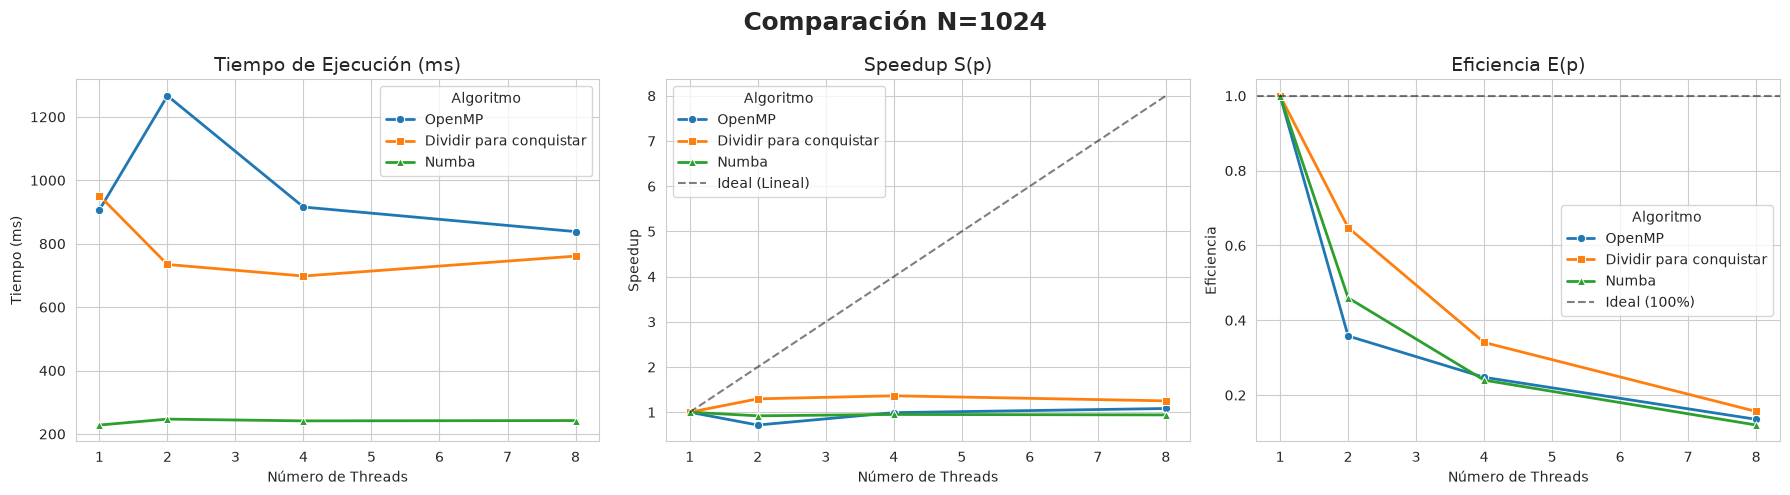

In [16]:
plot_comparacion_paralela(dataset_1024, nombre_figura="comparacion_algoritmo_1024.png", titulo="Comparación N=1024")

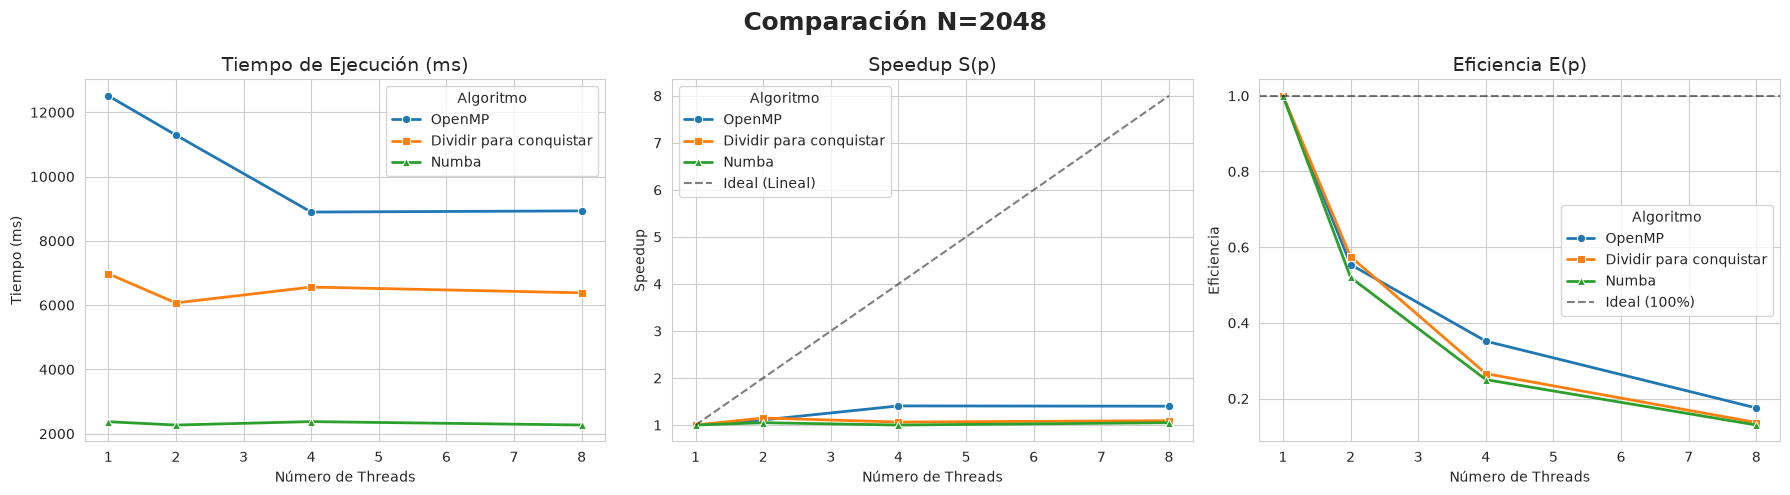

In [17]:
plot_comparacion_paralela(dataset_2048, nombre_figura="comparacion_algoritmo_2048.png", titulo="Comparación N=2048")

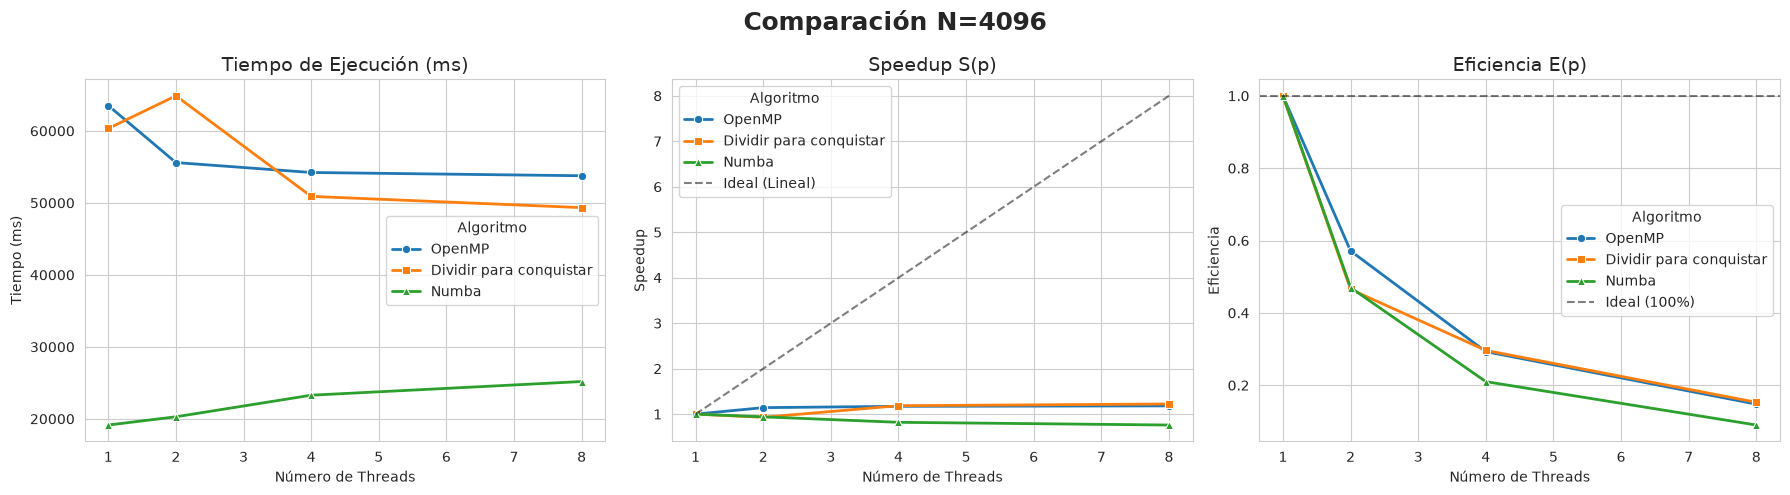

In [18]:
plot_comparacion_paralela(dataset_4096, nombre_figura="comparacion_algoritmo_4096.png", titulo="Comparación N=4096")